In [56]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [57]:
df = pd.read_csv(r'D:\NTI Machine\Laptop\laptopData.csv')

In [58]:
df.head()

,Unnamed: 0,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price
0,0.0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,71378.6832
1,1.0,Apple,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,47895.5232
2,2.0,HP,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,30636.0000
3,3.0,Apple,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,135195.3360
4,4.0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,96095.8080


In [59]:
df.drop(columns = ['Unnamed: 0'], inplace = True)

In [60]:
df.duplicated().sum()

58

In [61]:
df.drop_duplicates(inplace = True)

In [62]:
df.isnull().sum()

Company             1
TypeName            1
Inches              1
ScreenResolution    1
Cpu                 1
Ram                 1
Memory              1
Gpu                 1
OpSys               1
Weight              1
Price               1
dtype: int64

In [63]:
df.dropna(inplace=True)

In [64]:
df.head()

,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price
0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,71378.6832
1,Apple,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,47895.5232
2,HP,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,30636.0000
3,Apple,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,135195.3360
4,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,96095.8080


In [65]:
for col in df.select_dtypes("O").columns:
    print(f"{col} number of uniques: ", df[col].nunique())
    print(f"{col} uniques: ", df[col].unique())

Company number of uniques:  19
Company uniques:  ['Apple' 'HP' 'Acer' 'Asus' 'Dell' 'Lenovo' 'Chuwi' 'MSI' 'Microsoft'
 'Toshiba' 'Huawei' 'Xiaomi' 'Vero' 'Razer' 'Mediacom' 'Samsung' 'Google'
 'Fujitsu' 'LG']
TypeName number of uniques:  6
TypeName uniques:  ['Ultrabook' 'Notebook' 'Gaming' '2 in 1 Convertible' 'Workstation'
 'Netbook']
Inches number of uniques:  25
Inches uniques:  ['13.3' '15.6' '15.4' '14' '12' '17.3' '13.5' '12.5' '13' '18.4' '13.9'
 '11.6' '25.6' '35.6' '12.3' '27.3' '24' '33.5' '?' '31.6' '17' '15'
 '14.1' '11.3' '10.1']
ScreenResolution number of uniques:  40
ScreenResolution uniques:  ['IPS Panel Retina Display 2560x1600' '1440x900' 'Full HD 1920x1080'
 'IPS Panel Retina Display 2880x1800' '1366x768'
 'IPS Panel Full HD 1920x1080' 'IPS Panel Retina Display 2304x1440'
 'IPS Panel Full HD / Touchscreen 1920x1080'
 'Full HD / Touchscreen 1920x1080' 'Touchscreen / Quad HD+ 3200x1800'
 'Touchscreen 2256x1504' 'Quad HD+ / Touchscreen 3200x1800'
 'IPS Panel 1366x768'

In [66]:
splitCols = ['Ram','Weight','Memory']

In [67]:
df['Ram'] = df['Ram'].apply(lambda x : pd.to_numeric(x.split("GB")[0]))

In [68]:
df['Weight'] = df['Weight'].apply(lambda x : pd.to_numeric(x.split("kg")[0],errors='coerce'))

In [69]:
df.isnull().sum()

Company             0
TypeName            0
Inches              0
ScreenResolution    0
Cpu                 0
Ram                 0
Memory              0
Gpu                 0
OpSys               0
Weight              1
Price               0
dtype: int64

In [70]:
df[['Memory Size', 'Memory Type']] = df['Memory'].str.split(' ', n=1, expand=True)

In [71]:
df.drop(columns=['Memory'],inplace= True)

In [72]:
df

,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Gpu,OpSys,Weight,Price,Memory Size,Memory Type
0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8,Intel Iris Plus Graphics 640,macOS,1.37,71378.6832,128GB,SSD
1,Apple,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8,Intel HD Graphics 6000,macOS,1.34,47895.5232,128GB,Flash Storage
2,HP,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8,Intel HD Graphics 620,No OS,1.86,30636.0000,256GB,SSD
3,Apple,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16,AMD Radeon Pro 455,macOS,1.83,135195.3360,512GB,SSD
4,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8,Intel Iris Plus Graphics 650,macOS,1.37,96095.8080,256GB,SSD
...,...,...,...,...,...,...,...,...,...,...,...,...
1269,Asus,Notebook,15.6,1366x768,Intel Core i7 6500U 2.5GHz,4,Nvidia GeForce 920M,Windows 10,2.20,38378.6496,500GB,HDD
1270,Lenovo,2 in 1 Convertible,14,IPS Panel Full HD / Touchscreen 1920x1080,Intel Core i7 6500U 2.5GHz,4,Intel HD Graphics 520,Windows 10,1.80,33992.6400,128GB,SSD
1271,Lenovo,2 in 1 Convertible,13.3,IPS Panel Quad HD+ / Touchscreen 3200x1800,Intel Core i7 6500U 2.5GHz,16,Intel HD Graphics 520,Windows 10,1.30,79866.7200,512GB,SSD
1272,Lenovo,Notebook,14,1366x768,Intel Celeron Dual Core N3050 1.6GHz,2,Intel HD Graphics,Windows 10,1.50,12201.1200,64GB,Flash Storage


In [74]:


df['Memory Size'] = (
    df['Memory Size']
    .str.replace('TB', '', regex=False)
    .str.replace('GB', '', regex=False)

)

In [75]:
df['Memory Size'].unique()

array(['128', '256', '512', '500', '1', '64', '32', '2', '1.0', '16',
       '180', '?', '240', '8', '508'], dtype=object)

In [76]:
df.head()

,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Gpu,OpSys,Weight,Price,Memory Size,Memory Type
0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8,Intel Iris Plus Graphics 640,macOS,1.37,71378.6832,128,SSD
1,Apple,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8,Intel HD Graphics 6000,macOS,1.34,47895.5232,128,Flash Storage
2,HP,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8,Intel HD Graphics 620,No OS,1.86,30636.0000,256,SSD
3,Apple,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16,AMD Radeon Pro 455,macOS,1.83,135195.3360,512,SSD
4,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8,Intel Iris Plus Graphics 650,macOS,1.37,96095.8080,256,SSD


In [77]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1244 entries, 0 to 1273
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Company           1244 non-null   object 
 1   TypeName          1244 non-null   object 
 2   Inches            1244 non-null   object 
 3   ScreenResolution  1244 non-null   object 
 4   Cpu               1244 non-null   object 
 5   Ram               1244 non-null   int64  
 6   Gpu               1244 non-null   object 
 7   OpSys             1244 non-null   object 
 8   Weight            1243 non-null   float64
 9   Price             1244 non-null   float64
 10  Memory Size       1244 non-null   object 
 11  Memory Type       1243 non-null   object 
dtypes: float64(2), int64(1), object(9)
memory usage: 126.3+ KB


In [78]:
df['Memory Size'] = pd.to_numeric(df['Memory Size'],errors='coerce')

In [79]:
df['Inches'] = pd.to_numeric(df['Inches'],errors='coerce')

In [80]:
df.isnull().sum()

Company             0
TypeName            0
Inches              1
ScreenResolution    0
Cpu                 0
Ram                 0
Gpu                 0
OpSys               0
Weight              1
Price               0
Memory Size         1
Memory Type         1
dtype: int64

In [81]:
df = df.dropna()

In [82]:
df

,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Gpu,OpSys,Weight,Price,Memory Size,Memory Type
0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8,Intel Iris Plus Graphics 640,macOS,1.37,71378.6832,128.0,SSD
1,Apple,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8,Intel HD Graphics 6000,macOS,1.34,47895.5232,128.0,Flash Storage
2,HP,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8,Intel HD Graphics 620,No OS,1.86,30636.0000,256.0,SSD
3,Apple,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16,AMD Radeon Pro 455,macOS,1.83,135195.3360,512.0,SSD
4,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8,Intel Iris Plus Graphics 650,macOS,1.37,96095.8080,256.0,SSD
...,...,...,...,...,...,...,...,...,...,...,...,...
1269,Asus,Notebook,15.6,1366x768,Intel Core i7 6500U 2.5GHz,4,Nvidia GeForce 920M,Windows 10,2.20,38378.6496,500.0,HDD
1270,Lenovo,2 in 1 Convertible,14.0,IPS Panel Full HD / Touchscreen 1920x1080,Intel Core i7 6500U 2.5GHz,4,Intel HD Graphics 520,Windows 10,1.80,33992.6400,128.0,SSD
1271,Lenovo,2 in 1 Convertible,13.3,IPS Panel Quad HD+ / Touchscreen 3200x1800,Intel Core i7 6500U 2.5GHz,16,Intel HD Graphics 520,Windows 10,1.30,79866.7200,512.0,SSD
1272,Lenovo,Notebook,14.0,1366x768,Intel Celeron Dual Core N3050 1.6GHz,2,Intel HD Graphics,Windows 10,1.50,12201.1200,64.0,Flash Storage


In [87]:
df['Memory Size'] = df['Memory Size'].astype(float)

df.loc[df['Memory Size'] < 8, 'Memory Size'] *= 1024

C:\Users\yawaa\AppData\Local\Temp\ipykernel_22200\4258882281.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Memory Size'] = df['Memory Size'].astype(float)


In [88]:
df['Memory Size'].unique()

array([ 128.,  256.,  512.,  500., 1024.,   64.,   32., 2048.,   16.,
        180.,  240.,    8.,  508.])

In [90]:
df.isnull().sum()

Company             0
TypeName            0
Inches              0
ScreenResolution    0
Cpu                 0
Ram                 0
Gpu                 0
OpSys               0
Weight              0
Price               0
Memory Size         0
Memory Type         0
dtype: int64

## Encoding and scaling for model training

`Price` is the regression target. The data is split before preprocessing; the encoder and scaler are fitted on the training set only, then applied to the test set. This prevents preprocessing leakage and leaves `X_train_processed`, `X_test_processed`, `y_train`, and `y_test` ready for model training and evaluation.

In [92]:
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder, StandardScaler

target = "Price"
X = df.drop(columns=[target]).copy()
y = df[target].copy()

categorical_features = X.select_dtypes(include=["object", "category"]).columns.tolist()
numeric_features = X.select_dtypes(include=[np.number]).columns.tolist()

if X.isna().any().any() or y.isna().any():
    raise ValueError("Handle missing values before splitting and preprocessing.")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_features),
        (
            "categorical",
            OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1),
            categorical_features,
        ),
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)
feature_names = preprocessor.get_feature_names_out()

print(f"Training features: {X_train_processed.shape}")
print(f"Test features: {X_test_processed.shape}")
print(f"Training targets: {y_train.shape}; test targets: {y_test.shape}")
print(f"Numeric features scaled: {numeric_features}")
print(f"Categorical features label-encoded: {categorical_features}")
print(f"Encoded feature names available: {len(feature_names)}")

Training features: (992, 11)
Test features: (249, 11)
Training targets: (992,); test targets: (249,)
Numeric features scaled: ['Inches', 'Ram', 'Weight', 'Memory Size']
Categorical features label-encoded: ['Company', 'TypeName', 'ScreenResolution', 'Cpu', 'Gpu', 'OpSys', 'Memory Type']
Encoded feature names available: 11


In [94]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.linear_model import LinearRegression , Lasso ,Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.experimental import enable_hist_gradient_boosting  # Needed for HistGB
from sklearn.ensemble import (RandomForestRegressor,ExtraTreesRegressor,BaggingRegressor,
                              AdaBoostRegressor ,GradientBoostingRegressor,HistGradientBoostingRegressor
                              , VotingRegressor,StackingRegressor)
#import xgboost as xgb
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
#import lightgbm as lgb
from lightgbm import LGBMRegressor
from tqdm import tqdm

e:\anaconda\Lib\site-packages\sklearn\experimental\enable_hist_gradient_boosting.py:18: UserWarning: Since version 1.0, it is not needed to import enable_hist_gradient_boosting anymore. HistGradientBoostingClassifier and HistGradientBoostingRegressor are now stable and can be normally imported from sklearn.ensemble.
  warnings.warn(


In [95]:
models ={
    "Linear Regression":LinearRegression(),
    "Lasso":Lasso(),
    "Ridge":Ridge(),
    "KNN":KNeighborsRegressor(n_neighbors=5,metric='minkowski',p=1), #  minkowski , euclidean , manhattan
    "SVM":SVR(kernel='linear', C=100, gamma=1), # kernel='rbf' / kernel='poly', degree=4 / kernel='sigmoid
    "Decision Tree":DecisionTreeRegressor(criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "Random Forest":RandomForestRegressor(n_estimators=50,criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "ExtraTrees": ExtraTreesRegressor(n_estimators=100, random_state=42),
    "Bagging": BaggingRegressor(estimator=DecisionTreeRegressor(criterion='squared_error',max_depth=10),n_estimators=50, random_state=42),
    "AdaBoost": AdaBoostRegressor(n_estimators=15, random_state=42),
    "GradientBoosting": GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=100, learning_rate=0.1, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42, verbosity=0),
    "CatBoost": CatBoostRegressor(verbose=0, iterations=100, learning_rate=0.1, random_state=42),
    "LightGBM": LGBMRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
}

In [96]:
# Metrics function
def regression_metrics(model, X, y_actual):
    y_pred = model.predict(X)
    MAE = mean_absolute_error(y_actual, y_pred)
    MSE = mean_squared_error(y_actual, y_pred)
    RMSE = np.sqrt(MSE)
    R2 = r2_score(y_actual, y_pred)
    return MAE, MSE, RMSE, R2

  0%|          | 0/15 [00:00<?, ?it/s]

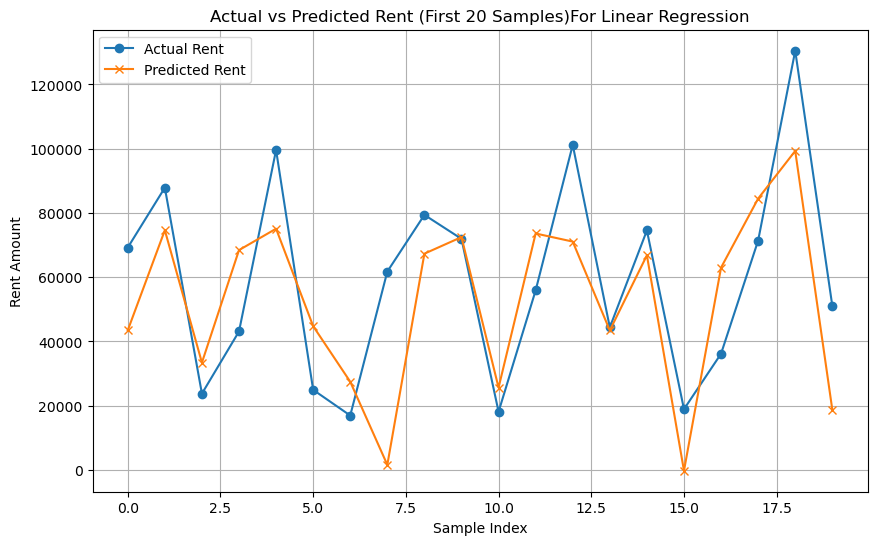

  7%|▋         | 1/15 [00:00<00:04,  2.95it/s]

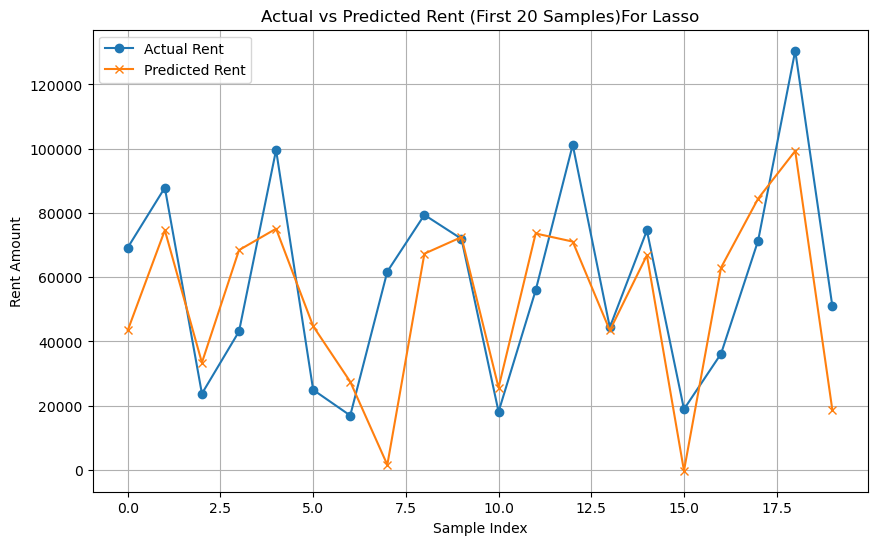

 13%|█▎        | 2/15 [00:00<00:03,  3.87it/s]

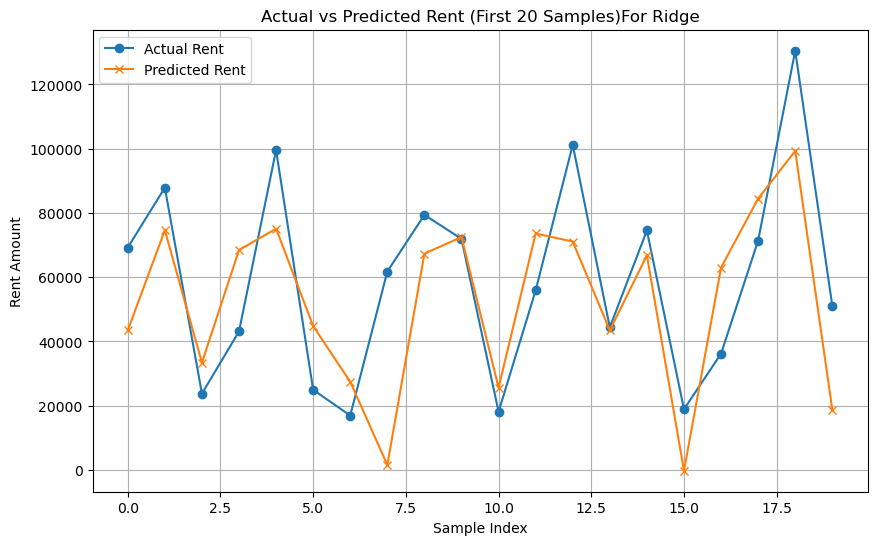

 20%|██        | 3/15 [00:00<00:03,  3.91it/s]

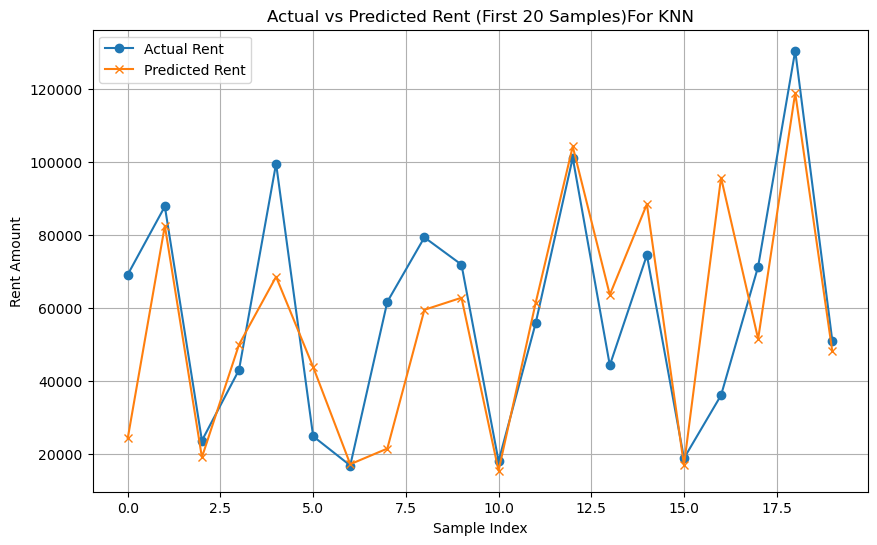

 27%|██▋       | 4/15 [00:01<00:03,  3.47it/s]

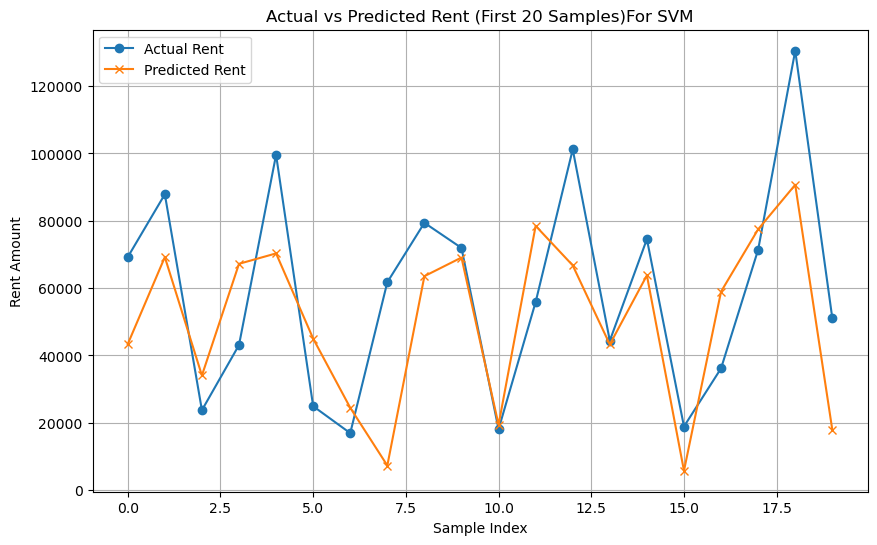

 33%|███▎      | 5/15 [00:01<00:03,  3.21it/s]

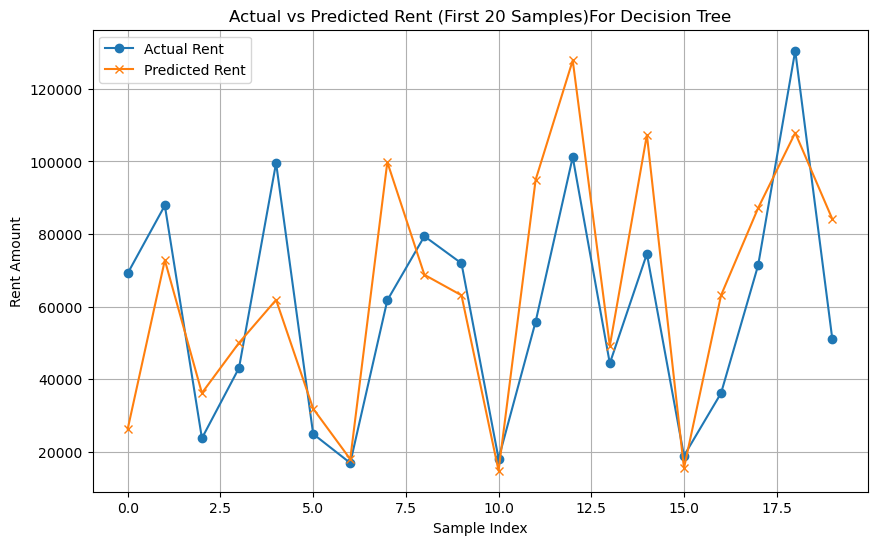

 40%|████      | 6/15 [00:01<00:02,  3.63it/s]

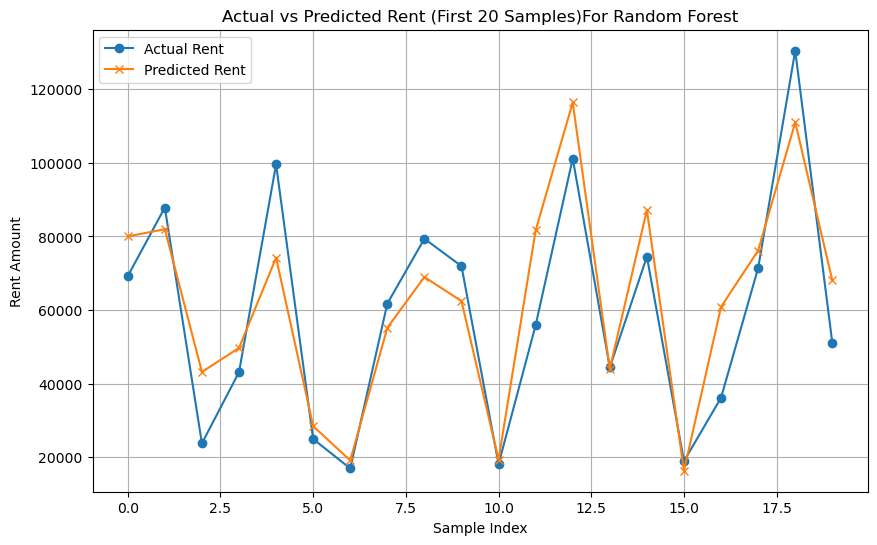

 47%|████▋     | 7/15 [00:02<00:02,  3.29it/s]

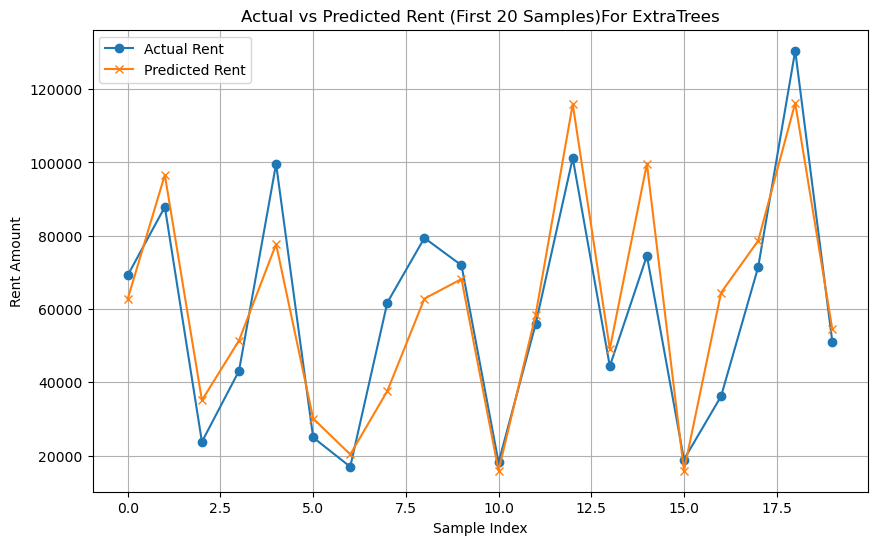

 53%|█████▎    | 8/15 [00:02<00:02,  2.58it/s]

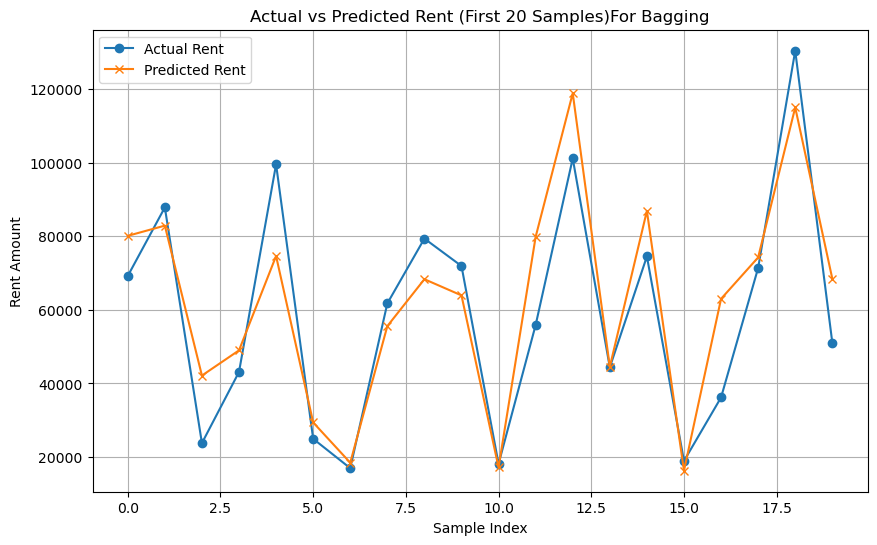

 60%|██████    | 9/15 [00:03<00:02,  2.53it/s]

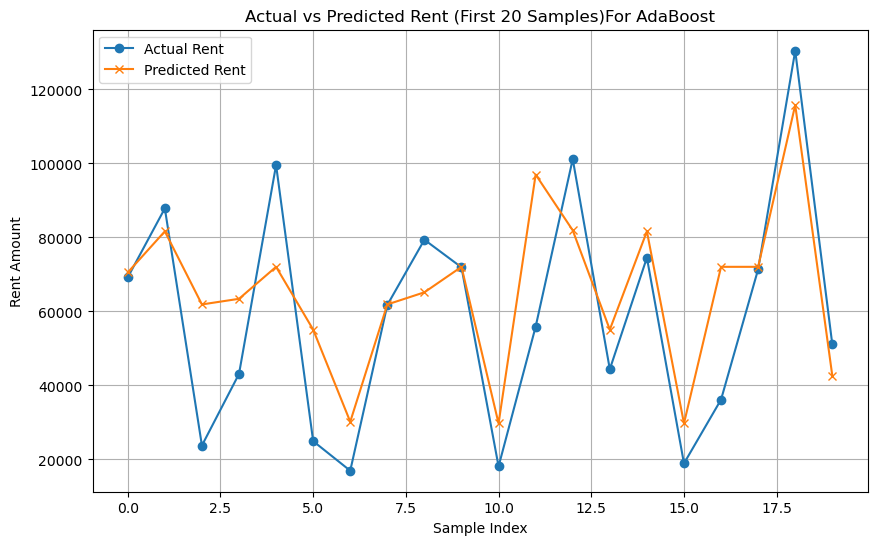

 67%|██████▋   | 10/15 [00:03<00:01,  2.89it/s]

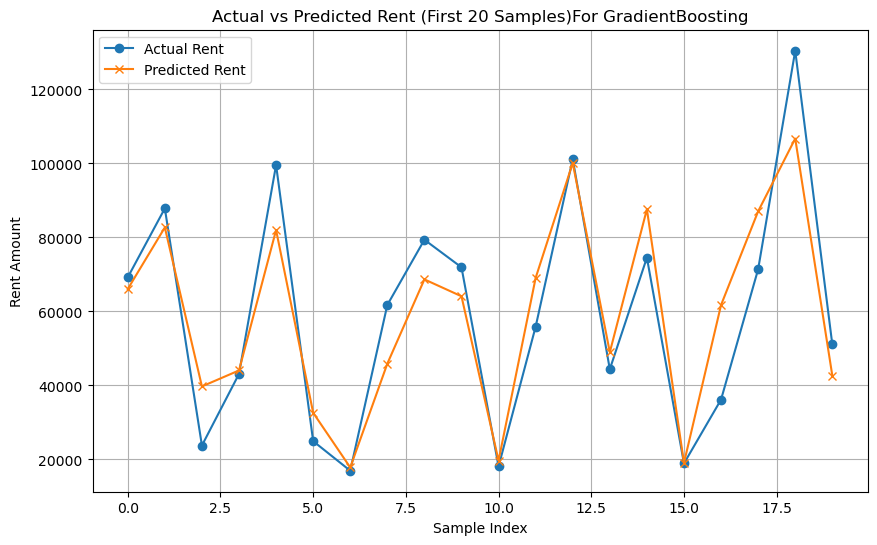

 73%|███████▎  | 11/15 [00:03<00:01,  2.82it/s]e:\anaconda\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "e:\anaconda\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "e:\anaconda\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "e:\anaconda\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "e:\anaconda\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, a

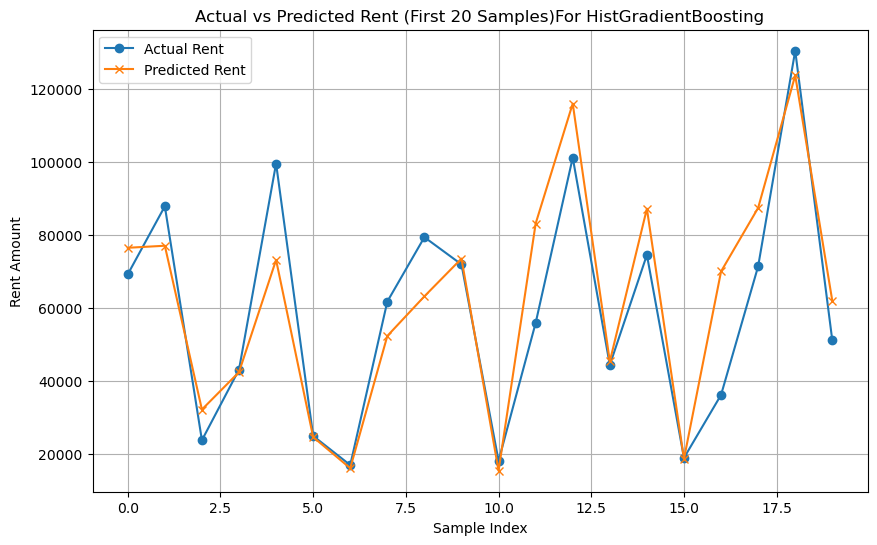

 80%|████████  | 12/15 [00:04<00:01,  1.81it/s]

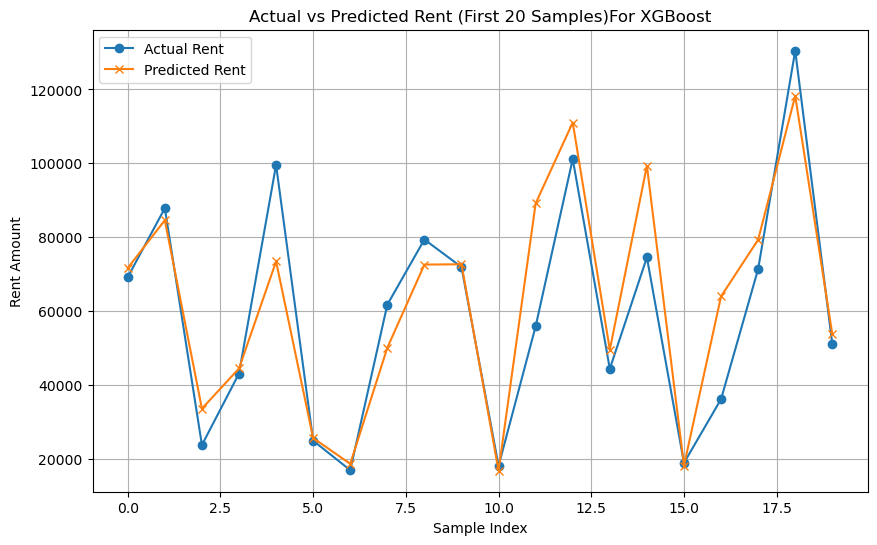

 87%|████████▋ | 13/15 [00:06<00:01,  1.23it/s]

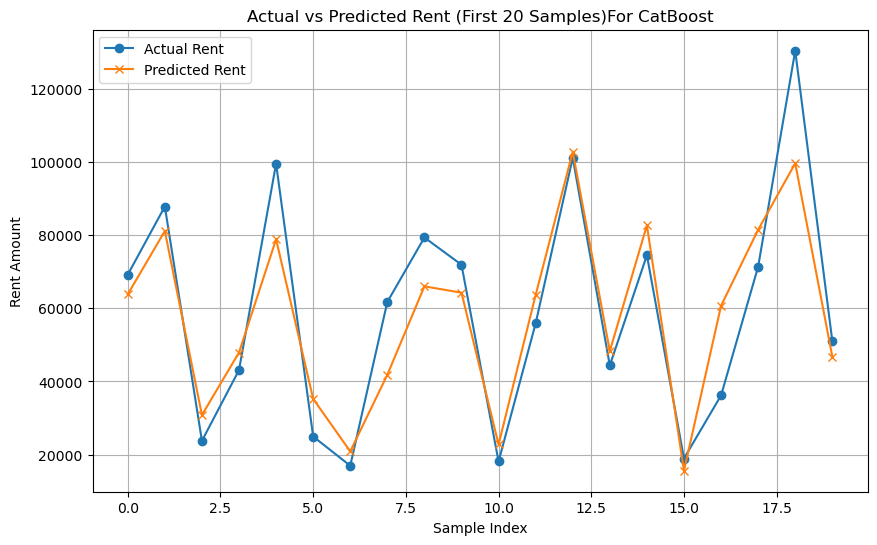

 93%|█████████▎| 14/15 [00:06<00:00,  1.31it/s]

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000458 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 342
[LightGBM] [Info] Number of data points in the train set: 992, number of used features: 11
[LightGBM] [Info] Start training from score 61067.389669


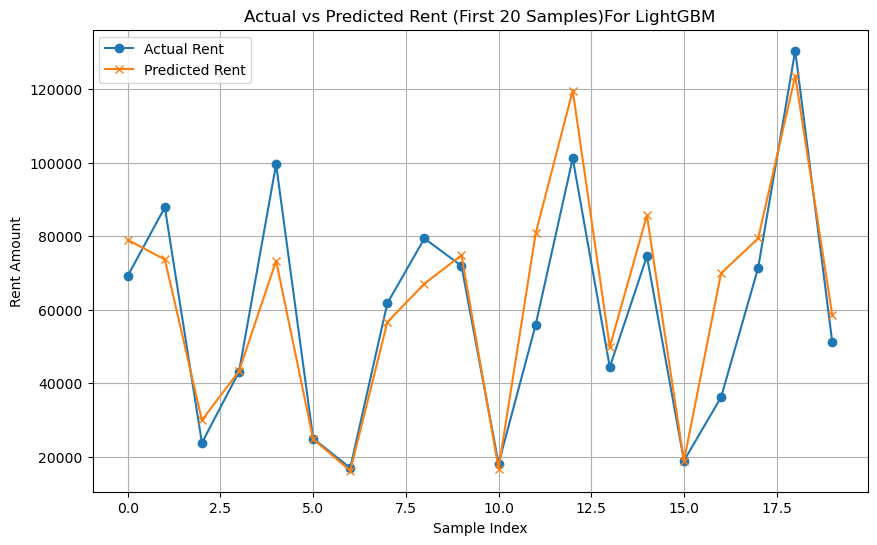

100%|██████████| 15/15 [00:07<00:00,  2.08it/s]


In [98]:
errors={}
for model_name , model in tqdm(models.items()):
    model.fit(X_train_processed,y_train)
    MAE_Train, MSE_Train, RMSE_Train, R_Train = regression_metrics(model, X_train_processed, y_train)
    MAE_Test, MSE_Test, RMSE_Test, R_Test = regression_metrics(model, X_test_processed, y_test)
    
    errors[model_name] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R_Train,
        "R2 Test":R_Test
    }

    #Plotting Actual vs Predicted for first 20 test samples
    y_test_plot = y_test.values[:20]
    y_pred_plot = model.predict(X_test_processed[:20])

    plt.figure(figsize=(10,6))
    plt.plot(range(20), y_test_plot, label='Actual Rent', marker='o')
    plt.plot(range(20), y_pred_plot, label='Predicted Rent', marker='x')
    plt.xlabel('Sample Index')
    plt.ylabel('Rent Amount')
    plt.title('Actual vs Predicted Rent (First 20 Samples)For '+ model_name)
    plt.legend()
    plt.grid()
    plt.show()

In [99]:
error = pd.DataFrame(errors)

In [100]:
error

,Linear Regression,Lasso,Ridge,KNN,SVM,Decision Tree,Random Forest,ExtraTrees,Bagging,AdaBoost,GradientBoosting,HistGradientBoosting,XGBoost,CatBoost,LightGBM
MAE Train,1.637208e+04,1.637218e+04,1.637488e+04,9.892517e+03,1.629317e+04,4.660994e+03,5.906502e+03,1.724016e+02,5.837799e+03,1.644897e+04,7.914389e+03,5.489335e+03,3.955931e+03,8.370803e+03,5.521523e+03
MAE Test,1.646520e+04,1.646519e+04,1.646620e+04,1.320642e+04,1.611025e+04,1.256992e+04,9.962083e+03,9.394408e+03,1.002028e+04,1.707798e+04,1.063511e+04,9.567583e+03,8.687667e+03,1.060018e+04,9.537240e+03
MSE Train,5.500112e+08,5.500112e+08,5.500117e+08,2.306539e+08,5.983622e+08,6.475637e+07,7.374457e+07,8.504385e+05,7.362326e+07,4.082610e+08,1.155025e+08,7.566250e+07,3.128906e+07,1.316905e+08,7.652606e+07
MSE Test,5.080964e+08,5.081053e+08,5.082143e+08,4.623108e+08,5.386570e+08,4.598245e+08,2.631160e+08,2.309516e+08,2.646982e+08,5.233030e+08,2.815342e+08,2.318098e+08,2.089319e+08,2.623429e+08,2.248589e+08
RMSE Train,2.345232e+04,2.345232e+04,2.345233e+04,1.518729e+04,2.446144e+04,8.047134e+03,8.587466e+03,9.221922e+02,8.580400e+03,2.020547e+04,1.074721e+04,8.698419e+03,5.593662e+03,1.147565e+04,8.747917e+03
RMSE Test,2.254099e+04,2.254119e+04,2.254361e+04,2.150141e+04,2.320899e+04,2.144352e+04,1.622085e+04,1.519709e+04,1.626955e+04,2.287582e+04,1.677898e+04,1.522530e+04,1.445448e+04,1.619700e+04,1.499530e+04
R2 Train,6.124719e-01,6.124719e-01,6.124715e-01,8.374853e-01,5.784046e-01,9.543738e-01,9.480409e-01,9.994008e-01,9.481264e-01,7.123465e-01,9.186190e-01,9.466895e-01,9.779543e-01,9.072132e-01,9.460811e-01
R2 Test,6.128174e-01,6.128107e-01,6.127275e-01,6.477072e-01,5.895294e-01,6.496018e-01,7.994988e-01,8.240089e-01,7.982931e-01,6.012296e-01,7.854637e-01,8.233549e-01,8.407885e-01,8.000880e-01,8.286517e-01
